# Breast Cancer Histopathology Image Classification with CNN

Step 1: Import Libraries

In [2]:
# Import required libraries
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 2.4/351.2 MB 11.9 MB/s eta 0:00:30
    --------------------------------------- 5.0/351.2 MB 11.9 MB/s eta 0:00:30
    --------------------------------------- 7.6/351.2 MB 11.9 MB/s eta 0:00:29
   - -------------------------------------- 10.2/351.2 MB 11.8 MB/s eta 0:00:29
   - -------------------------------------- 12.6/351.2 MB 11.8 MB/s eta 0:00:29
   - -------------------------------------- 14.9/351.2 MB 11.8 MB/s eta 0:00:29
   -- ------------------------------------- 17.6/351.2 MB 11.8 MB/s eta 0:00:29
   -- ------------------------------------- 19.9/351.2 MB 11.8 MB/s eta 0:00:29
   -- ------------------------------------- 22.5/351.2 MB 11.8 MB/s eta 0:00:28
   -- ------------------------------------- 24.9/351.2 MB 11.8 MB/s eta 0:00:28
   --- ------------------------------------ 27.3/351.2

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
googleapis-common-protos 1.70.0 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-api-core 2.25.1 requires protobuf!=3.20.0,!=3.20.1,!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.19.5, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
proto-plus 1.26.1 requires protobuf<7.0.0,>=3.19.0, but you have protobuf 7.36

In [1]:
# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [7]:
# Check Downloads folder

download_path = r"C:\Users\utkri\Downloads\archive (2)"

print("Files and folders available in Downloads:\n")

for item in os.listdir(download_path):
    print(item)

Files and folders available in Downloads:

Breast_HistoPathology_Images_Analysis_CNN_Model readme.md
Breast_HistoPathology_Images_Analysis_with_CNN_Model__Kaggle__Dataset.ipynb


In [1]:
import os

dataset_path = r"C:\Users\utkri\Downloads\archive (2)"

image_extensions = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

image_count = 0
folders = []

for root, dirs, files in os.walk(dataset_path):
    for folder in dirs:
        folders.append(os.path.join(root, folder))

    for file in files:
        if file.lower().endswith(image_extensions):
            image_count += 1

print("Total folders:", len(folders))
print("Total image files:", image_count)

print("\nFirst 15 folders:")
for folder in folders[:15]:
    print(folder)

Total folders: 0
Total image files: 0

First 15 folders:


In [7]:
# Check Downloads folder

download_path = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

print("Files and folders available in Downloads:\n")

for item in os.listdir(download_path):
    print(item) 

Files and folders available in Downloads:

10253
10254
10255
10256
10257
10258
10259
10260
10261
10262
10264
10268
10269
10272
10273
10274
10275
10276
10277
10278
10279
10282
10285
10286
10288
10290
10291
10292
10293
10295
10299
10300
10301
10302
10303
10304
10305
10306
10307
10308
12241
12242
12626
12748
12749
12750
12751
12752
12810
12811
12817
12818
12819
12820
12821
12822
12823
12824
12826
12867
12868
12869
12870
12871
12872
12873
12875
12876
12877
12878
12879
12880
12881
12882
12883
12884
12886
12890
12891
12892
12893
12894
12895
12896
12897
12898
12900
12901
12905
12906
12907
12908
12909
12910
12911
12929
12930
12931
12932
12933
12934
12935
12947
12948
12949
12951
12954
12955
13018
13019
13020
13021
13022
13023
13024
13025
13106
13400
13401
13402
13403
13404
13458
13459
13460
13461
13462
13591
13613
13616
13617
13666
13687
13688
13689
13691
13692
13693
13694
13916
14078
14079
14081
14082
14153
14154
14155
14156
14157
14188
14189
14190
14191
14192
14209
14210
14211
14212
14213
143

In [8]:
# Set dataset path

dataset_path = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

# Get patient folders

patient_folders = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

print("Total Patients:", len(patient_folders))

# Inspect first patient folder

first_patient = patient_folders[0]
patient_path = os.path.join(dataset_path, first_patient)

print("\nPatient ID:", first_patient)
print("Subfolders:", os.listdir(patient_path))

# Count image files

image_extensions = (".png", ".jpg", ".jpeg")

total_images = 0

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            total_images += 1

print("\nTotal Images:", total_images)

Total Patients: 279

Patient ID: 10253
Subfolders: ['0', '1']

Total Images: 277524


# Load and visualize histopathology images

In [9]:
from PIL import Image
import random

# Collect image paths for both classes

class_0_images = []
class_1_images = []

for patient in patient_folders:
    patient_path = os.path.join(dataset_path, patient)

    for label in ["0", "1"]:
        class_path = os.path.join(patient_path, label)

        if os.path.exists(class_path):
            for file in os.listdir(class_path):
                if file.lower().endswith((".png", ".jpg", ".jpeg")):
                    image_path = os.path.join(class_path, file)

                    if label == "0":
                        class_0_images.append(image_path)
                    else:
                        class_1_images.append(image_path)

print("Class 0 Images:", len(class_0_images))
print("Class 1 Images:", len(class_1_images))
print("Total Images:", len(class_0_images) + len(class_1_images))

Class 0 Images: 198738
Class 1 Images: 78786
Total Images: 277524


In [11]:
import matplotlib.pyplot as plt
import random
from PIL import Image

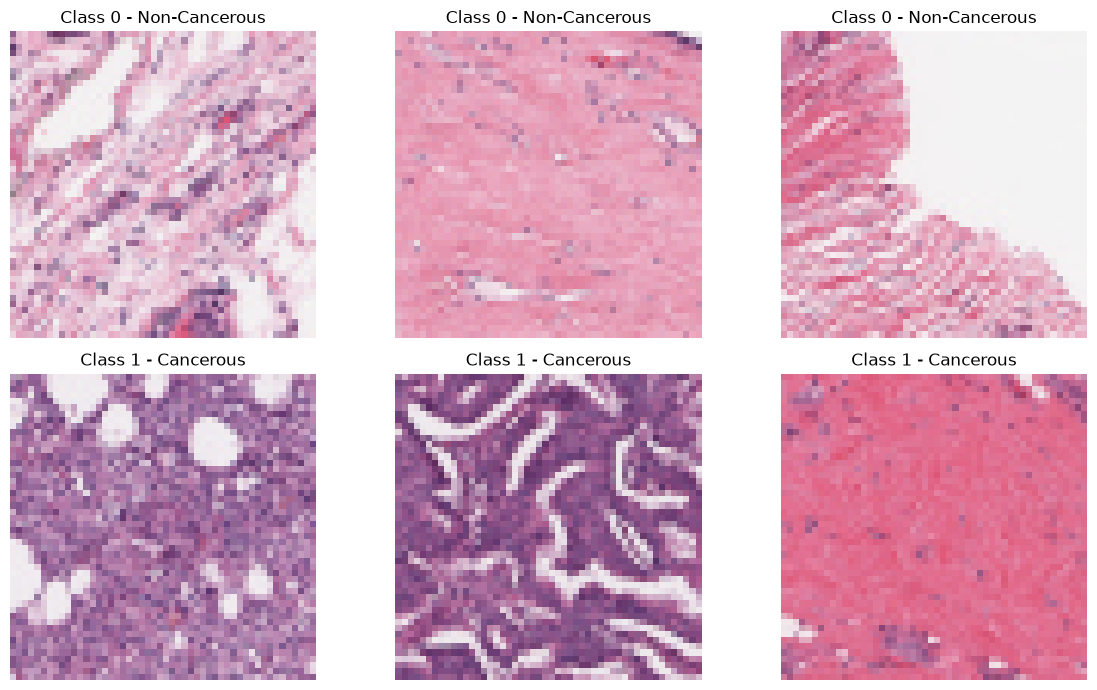

In [12]:
# Select 3 images from each class

sample_0 = random.sample(class_0_images, 3)
sample_1 = random.sample(class_1_images, 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, img_path in enumerate(sample_0):
    img = Image.open(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title("Class 0 - Non-Cancerous")
    axes[0, i].axis("off")

for i, img_path in enumerate(sample_1):
    img = Image.open(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title("Class 1 - Cancerous")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show() 

In [13]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import os

# Combine image paths and labels

all_images = class_0_images + class_1_images

all_labels = (
    [0] * len(class_0_images) +
    [1] * len(class_1_images)
)

# Extract patient ID from each image path

patient_ids = [
    os.path.basename(
        os.path.dirname(os.path.dirname(path))
    )
    for path in all_images
]

# Convert into NumPy arrays

X = np.array(all_images)
y = np.array(all_labels)
groups = np.array(patient_ids)

# Split data patient-wise

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

train_patients = set(groups[train_idx])
test_patients = set(groups[test_idx])

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("\nTraining Patients:", len(train_patients))
print("Testing Patients:", len(test_patients))

print(
    "\nPatient Overlap:",
    len(train_patients.intersection(test_patients))
)

print("\nTraining Class Distribution:")
print("Class 0:", np.sum(y_train == 0))
print("Class 1:", np.sum(y_train == 1))

print("\nTesting Class Distribution:")
print("Class 0:", np.sum(y_test == 0))
print("Class 1:", np.sum(y_test == 1))

Training Images: 220033
Testing Images: 57491

Training Patients: 223
Testing Patients: 56

Patient Overlap: 0

Training Class Distribution:
Class 0: 157575
Class 1: 62458

Testing Class Distribution:
Class 0: 41163
Class 1: 16328


In [15]:
import tensorflow as tf
import numpy as np
import os

print("TensorFlow Version:", tf.__version__)
print("TensorFlow imported successfully!")

TensorFlow Version: 2.21.0
TensorFlow imported successfully!


In [16]:
IMG_SIZE = 50
BATCH_SIZE = 64

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Training dataset

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(10000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Testing dataset

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = (
    test_dataset
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [17]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (64, 50, 50, 3)
Label batch shape: (64,)
Minimum pixel value: 0.02745098
Maximum pixel value: 1.0


In [19]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("CNN layers imported successfully!")

CNN layers imported successfully!


In [20]:
cnn_model = Sequential([

    tf.keras.layers.Input(shape=(50, 50, 3)),

    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Third Convolutional Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [21]:
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,649 (1.36 MB)

 Trainable params: 355,649 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(0.6981849912739965), np.int64(1): np.float64(1.761447692849595)}


In [23]:
from sklearn.model_selection import GroupShuffleSplit

# Patient-wise split of training data

train_groups = groups[train_idx]

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

new_train_idx, val_idx = next(
    splitter_val.split(X_train, y_train, train_groups)
)

X_val = X_train[val_idx]
y_val = y_train[val_idx]

X_train_final = X_train[new_train_idx]
y_train_final = y_train[new_train_idx]

print("Final Training Images:", len(X_train_final))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

print(
    "Patient overlap (train-validation):",
    len(set(train_groups[new_train_idx]) & set(train_groups[val_idx]))
)

Final Training Images: 181549
Validation Images: 38484
Testing Images: 57491
Patient overlap (train-validation): 0


In [24]:
# Updated training dataset

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_final, y_train_final)
)

train_dataset = (
    train_dataset
    .shuffle(10000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = (
    val_dataset
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and validation datasets are ready!")

Training and validation datasets are ready!


# Train CNN Model

In [25]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/3


C:\Users\utkri\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2837/2837 ━━━━━━━━━━━━━━━━━━━━ 696s 244ms/step - accuracy: 0.9700 - auc: 0.9951 - loss: 0.0742 - precision: 0.9174 - recall: 0.9837 - val_accuracy: 0.2748 - val_auc: 0.7992 - val_loss: 3.5186 - val_precision: 0.2747 - val_recall: 1.0000
Epoch 2/3
2837/2837 ━━━━━━━━━━━━━━━━━━━━ 273s 96ms/step - accuracy: 0.9684 - auc: 0.9944 - loss: 0.0990 - precision: 0.9121 - recall: 0.9842 - val_accuracy: 0.2747 - val_auc: 0.7113 - val_loss: 4.2216 - val_precision: 0.2747 - val_recall: 1.0000
Epoch 3/3
2837/2837 ━━━━━━━━━━━━━━━━━━━━ 268s 94ms/step - accuracy: 0.9654 - auc: 0.9944 - loss: 0.0811 - precision: 0.8994 - recall: 0.9897 - val_accuracy: 0.2754 - val_auc: 0.8128 - val_loss: 3.2677 - val_precision: 0.2749 - val_recall: 0.9999


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
print("Actual Validation Distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nPredicted Validation Distribution:")
print(pd.Series(y_val_pred).value_counts().sort_index())

Actual Validation Distribution:
0    27911
1    10573
Name: count, dtype: int64

Predicted Validation Distribution:
0       27
1    38457
Name: count, dtype: int64


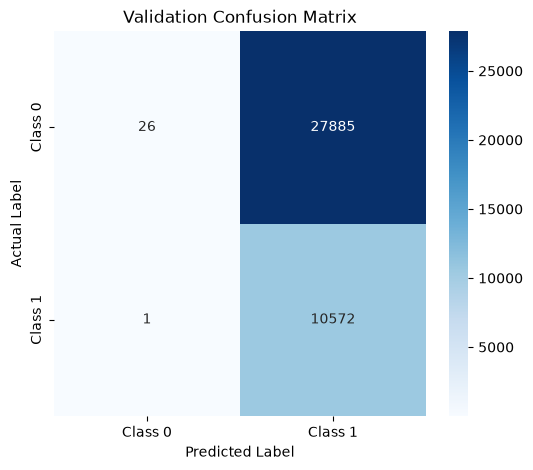

               precision    recall  f1-score   support

Non-Cancerous       0.96      0.00      0.00     27911
    Cancerous       0.27      1.00      0.43     10573

     accuracy                           0.28     38484
    macro avg       0.62      0.50      0.22     38484
 weighted avg       0.77      0.28      0.12     38484



In [29]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Validation Confusion Matrix")
plt.show()

print(classification_report(
    y_val,
    y_val_pred,
    target_names=['Non-Cancerous', 'Cancerous']
))

In [30]:
# Separate predicted probabilities by actual class

probabilities = y_val_prob.flatten()

class_0_prob = probabilities[y_val == 0]
class_1_prob = probabilities[y_val == 1]

print("Class 0 Probability Statistics:")
print(pd.Series(class_0_prob).describe())

print("\nClass 1 Probability Statistics:")
print(pd.Series(class_1_prob).describe())

Class 0 Probability Statistics:
count    27911.000000
mean         0.974528
std          0.034346
min          0.235274
25%          0.962897
50%          0.979604
75%          0.995398
max          0.999853
dtype: float64

Class 1 Probability Statistics:
count    10573.000000
mean         0.995997
std          0.010697
min          0.484437
25%          0.997224
50%          0.999253
75%          0.999690
max          0.999853
dtype: float64


In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

for threshold in thresholds:

    predictions = (probabilities >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", accuracy_score(y_val, predictions))
    print("Precision:", precision_score(y_val, predictions, zero_division=0))
    print("Recall:", recall_score(y_val, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_val, predictions, zero_division=0))


Threshold: 0.1
Accuracy: 0.274737553268891
Precision: 0.274737553268891
Recall: 1.0
F1 Score: 0.4310495953686528

Threshold: 0.3
Accuracy: 0.2751013408169629
Precision: 0.2748375357421367
Recall: 1.0
F1 Score: 0.4311726444140856

Threshold: 0.5
Accuracy: 0.275387173890448
Precision: 0.2749044387237694
Recall: 0.9999054194646742
F1 Score: 0.4312461758107281

Threshold: 0.7
Accuracy: 0.276504521359526
Precision: 0.27520045819014893
Recall: 0.9998108389293483
F1 Score: 0.4316015106665306

Threshold: 0.9
Accuracy: 0.2858070886602224
Precision: 0.2777193628095263
Recall: 0.9992433557173933
F1 Score: 0.43463951455312144


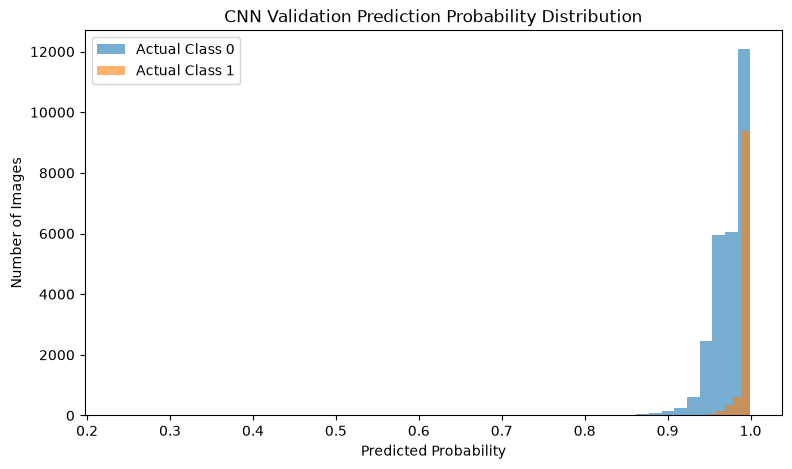

In [32]:
plt.figure(figsize=(9, 5))

plt.hist(
    class_0_prob,
    bins=50,
    alpha=0.6,
    label="Actual Class 0"
)

plt.hist(
    class_1_prob,
    bins=50,
    alpha=0.6,
    label="Actual Class 1"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Number of Images")
plt.title("CNN Validation Prediction Probability Distribution")

plt.legend()
plt.show()

# Check training vs validation predictions

In [33]:
# Predict on one training batch and one validation batch

for train_images, train_labels in train_dataset.take(1):
    train_prob = cnn_model.predict(train_images, verbose=0).flatten()

for val_images, val_labels in val_dataset.take(1):
    val_prob = cnn_model.predict(val_images, verbose=0).flatten()

print("Training Prediction Statistics:")
print(pd.Series(train_prob).describe())

print("\nValidation Prediction Statistics:")
print(pd.Series(val_prob).describe())

Training Prediction Statistics:
count    64.000000
mean      0.987095
std       0.017566
min       0.890873
25%       0.981150
50%       0.993913
75%       0.998900
max       0.999802
dtype: float64

Validation Prediction Statistics:
count    64.000000
mean      0.963655
std       0.048832
min       0.664599
25%       0.958119
50%       0.969601
75%       0.987009
max       0.999321
dtype: float64


In [34]:
# Get predictions for one complete training dataset

y_train_prob_sample = cnn_model.predict(train_dataset, verbose=1).flatten()

y_train_actual_sample = np.concatenate([
    labels.numpy() for images, labels in train_dataset
])

y_train_pred_sample = (
    y_train_prob_sample >= 0.5
).astype(int)

print(classification_report(
    y_train_actual_sample,
    y_train_pred_sample,
    target_names=["Non-Cancerous", "Cancerous"]
))

2837/2837 ━━━━━━━━━━━━━━━━━━━━ 111s 39ms/step
               precision    recall  f1-score   support

Non-Cancerous       0.98      0.00      0.00    129664
    Cancerous       0.29      1.00      0.44     51885

     accuracy                           0.29    181549
    macro avg       0.63      0.50      0.22    181549
 weighted avg       0.78      0.29      0.13    181549



In [35]:
print("Training batch label distribution:")
print(pd.Series(train_labels.numpy()).value_counts().sort_index())

print("\nValidation batch label distribution:")
print(pd.Series(val_labels.numpy()).value_counts().sort_index())

Training batch label distribution:
0    64
Name: count, dtype: int64

Validation batch label distribution:
0    64
Name: count, dtype: int64


In [36]:
y_train_prob_sample = cnn_model.predict(
    train_dataset,
    verbose=1
).flatten()

y_train_actual_sample = np.concatenate([
    labels.numpy()
    for images, labels in train_dataset
])

y_train_pred_sample = (
    y_train_prob_sample >= 0.5
).astype(int)

print("Training prediction distribution:")
print(pd.Series(y_train_pred_sample).value_counts().sort_index())

print("\nTraining classification report:")

print(classification_report(
    y_train_actual_sample,
    y_train_pred_sample,
    target_names=["Non-Cancerous", "Cancerous"]
))

2837/2837 ━━━━━━━━━━━━━━━━━━━━ 109s 38ms/step
Training prediction distribution:
0       183
1    181366
Name: count, dtype: int64

Training classification report:
               precision    recall  f1-score   support

Non-Cancerous       0.98      0.00      0.00    129664
    Cancerous       0.29      1.00      0.44     51885

     accuracy                           0.29    181549
    macro avg       0.63      0.50      0.22    181549
 weighted avg       0.78      0.29      0.13    181549



In [37]:
patient_distribution = pd.DataFrame({
    "patient_id": groups,
    "label": y
})

print(
    patient_distribution
    .groupby(["patient_id", "label"])
    .size()
    .unstack(fill_value=0)
    .head(15)
)

label          0     1
patient_id            
10253        479    70
10254        772    76
10255        181    91
10256        351   117
10257        427   208
10258        422   108
10259       1434    31
10260        928   361
10261        590    56
10262       1053   754
10264        617   587
10268       2086    23
10269        904   250
10272       2150    25
10273        811  1211


In [38]:
print("Training prediction distribution:")
print(pd.Series(y_train_pred_sample).value_counts().sort_index())

print("\nTraining classification report:")

print(classification_report(
    y_train_actual_sample,
    y_train_pred_sample,
    target_names=["Non-Cancerous", "Cancerous"]
))

Training prediction distribution:
0       183
1    181366
Name: count, dtype: int64

Training classification report:
               precision    recall  f1-score   support

Non-Cancerous       0.98      0.00      0.00    129664
    Cancerous       0.29      1.00      0.44     51885

     accuracy                           0.29    181549
    macro avg       0.63      0.50      0.22    181549
 weighted avg       0.78      0.29      0.13    181549



In [39]:
distribution = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Class 0": [
        np.sum(y_train_final == 0),
        np.sum(y_val == 0),
        np.sum(y_test == 0)
    ],
    "Class 1": [
        np.sum(y_train_final == 1),
        np.sum(y_val == 1),
        np.sum(y_test == 1)
    ]
})

print(distribution)

      Dataset  Class 0  Class 1
0    Training   129664    51885
1  Validation    27911    10573
2     Testing    41163    16328


In [40]:
print("Sample image-label verification:\n")

for i in range(10):
    path = X_train_final[i]
    label = y_train_final[i]

    print(
        "Image:", os.path.basename(path),
        "| Folder:", os.path.basename(os.path.dirname(path)),
        "| Label:", label
    )

Sample image-label verification:

Image: 10253_idx5_x1001_y1001_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1051_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1101_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1151_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1201_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1251_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1301_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1351_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1501_class0.png | Folder: 0 | Label: 0
Image: 10253_idx5_x1001_y1551_class0.png | Folder: 0 | Label: 0


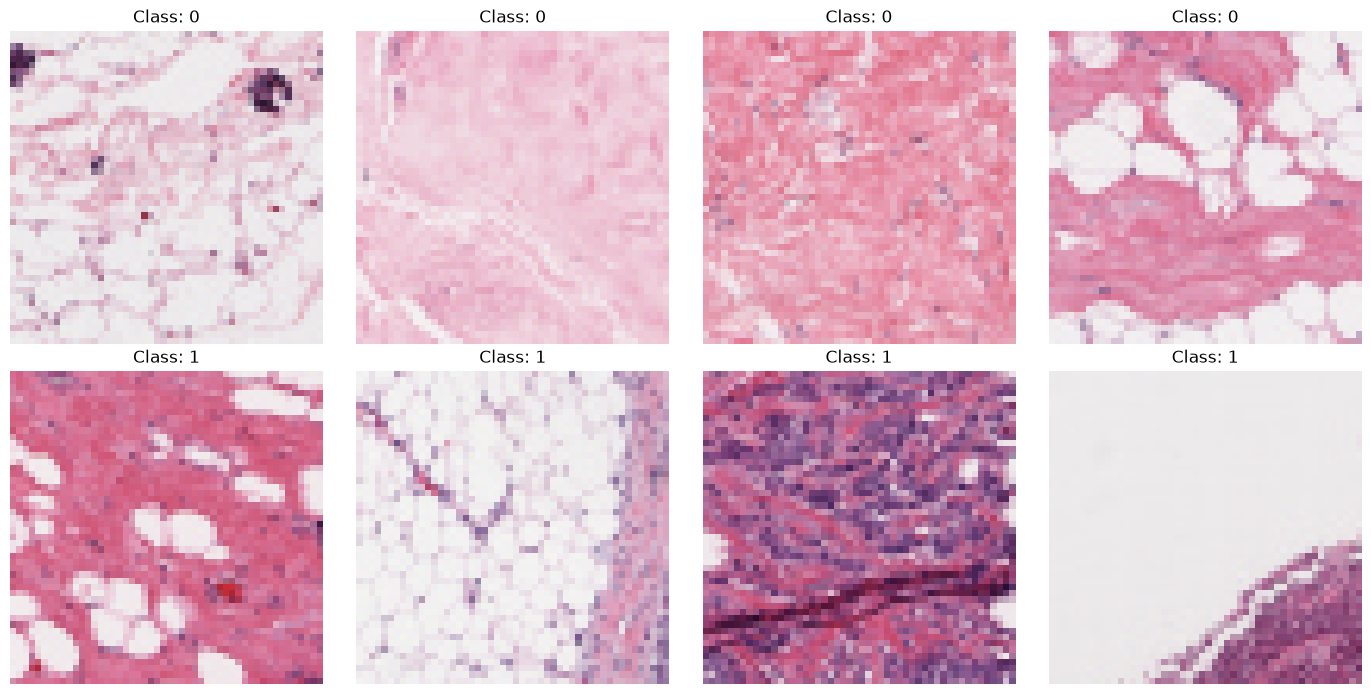

In [41]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Select 4 images from each class
class_0_indices = np.where(y_train_final == 0)[0]
class_1_indices = np.where(y_train_final == 1)[0]

sample_indices = (
    random.sample(list(class_0_indices), 4) +
    random.sample(list(class_1_indices), 4)
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, idx in zip(axes.flatten(), sample_indices):

    img_path = X_train_final[idx]
    label = int(y_train_final[idx])

    img = Image.open(img_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"Class: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
print("Image Path and Label Verification\n")

for idx in sample_indices:

    img_path = X_train_final[idx]

    folder_label = os.path.basename(
        os.path.dirname(img_path)
    )

    actual_label = int(y_train_final[idx])

    print(
        f"Folder: {folder_label} | "
        f"Assigned Label: {actual_label} | "
        f"Correct: {folder_label == str(actual_label)}"
    )

Image Path and Label Verification

Folder: 0 | Assigned Label: 0 | Correct: True
Folder: 0 | Assigned Label: 0 | Correct: True
Folder: 0 | Assigned Label: 0 | Correct: True
Folder: 0 | Assigned Label: 0 | Correct: True
Folder: 1 | Assigned Label: 1 | Correct: True
Folder: 1 | Assigned Label: 1 | Correct: True
Folder: 1 | Assigned Label: 1 | Correct: True
Folder: 1 | Assigned Label: 1 | Correct: True


# Prepare balanced training subset

In [43]:
import numpy as np

rng = np.random.default_rng(42)

class_0_idx = np.where(y_train_final == 0)[0]
class_1_idx = np.where(y_train_final == 1)[0]

n_samples = 15000

selected_0 = rng.choice(class_0_idx, n_samples, replace=False)
selected_1 = rng.choice(class_1_idx, n_samples, replace=False)

balanced_idx = np.concatenate([selected_0, selected_1])
rng.shuffle(balanced_idx)

X_train_balanced = X_train_final[balanced_idx]
y_train_balanced = y_train_final[balanced_idx]

print("Balanced Training Images:", len(X_train_balanced))
print("Class 0:", np.sum(y_train_balanced == 0))
print("Class 1:", np.sum(y_train_balanced == 1))

Balanced Training Images: 30000
Class 0: 15000
Class 1: 15000


In [44]:
train_dataset_balanced = tf.data.Dataset.from_tensor_slices(
    (X_train_balanced, y_train_balanced)
)

train_dataset_balanced = (
    train_dataset_balanced
    .shuffle(10000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

print("Balanced training dataset ready!")

Balanced training dataset ready!


In [45]:
cnn_model_v2 = Sequential([

    tf.keras.layers.Input(shape=(50, 50, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

cnn_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

cnn_model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,649 (1.36 MB)

 Trainable params: 355,649 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

# Train the improved CNN

In [46]:
early_stop_v2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history_v2 = cnn_model_v2.fit(
    train_dataset_balanced,
    validation_data=val_dataset,
    epochs=5,
    callbacks=[early_stop_v2]
)

Epoch 1/5


C:\Users\utkri\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


469/469 ━━━━━━━━━━━━━━━━━━━━ 61s 124ms/step - accuracy: 0.7469 - auc: 0.8195 - loss: 0.5272 - precision: 0.7805 - recall: 0.6871 - val_accuracy: 0.7766 - val_auc: 0.8441 - val_loss: 0.5105 - val_precision: 0.5636 - val_recall: 0.8268
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 66s 140ms/step - accuracy: 0.7885 - auc: 0.8519 - loss: 0.4778 - precision: 0.8009 - recall: 0.7680 - val_accuracy: 0.7956 - val_auc: 0.8505 - val_loss: 0.4672 - val_precision: 0.5987 - val_recall: 0.7762
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 62s 131ms/step - accuracy: 0.7897 - auc: 0.8601 - loss: 0.4668 - precision: 0.7989 - recall: 0.7743 - val_accuracy: 0.7509 - val_auc: 0.8573 - val_loss: 0.5516 - val_precision: 0.5283 - val_recall: 0.8722
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 60s 128ms/step - accuracy: 0.7948 - auc: 0.8651 - loss: 0.4592 - precision: 0.8035 - recall: 0.7806 - val_accuracy: 0.7913 - val_auc: 0.8640 - val_loss: 0.4616 - val_precision: 0.5866 - val_recall: 0.8139
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━

602/602 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step


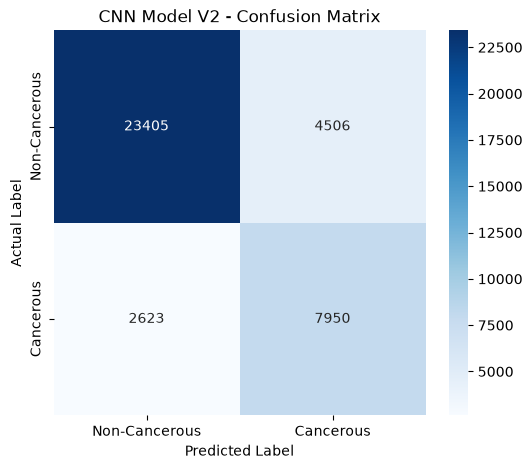

               precision    recall  f1-score   support

Non-Cancerous       0.90      0.84      0.87     27911
    Cancerous       0.64      0.75      0.69     10573

     accuracy                           0.81     38484
    macro avg       0.77      0.80      0.78     38484
 weighted avg       0.83      0.81      0.82     38484



In [47]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict using the trained CNN Model V2
y_val_prob_v2 = cnn_model_v2.predict(val_dataset)

y_val_pred_v2 = (y_val_prob_v2 >= 0.5).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_val, y_val_pred_v2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Cancerous', 'Cancerous'],
    yticklabels=['Non-Cancerous', 'Cancerous']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('CNN Model V2 - Confusion Matrix')
plt.show()

# Classification Report
print(classification_report(
    y_val,
    y_val_pred_v2,
    target_names=['Non-Cancerous', 'Cancerous']
))

# Final evaluation on test dataset

In [48]:
# Create test dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

# Evaluate CNN Model V2
test_results = cnn_model_v2.evaluate(test_dataset)

print("\nTest Evaluation Results:")
for name, value in zip(cnn_model_v2.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

899/899 ━━━━━━━━━━━━━━━━━━━━ 132s 147ms/step - accuracy: 0.8059 - auc: 0.8878 - loss: 0.4271 - precision: 0.6209 - recall: 0.8133

Test Evaluation Results:
loss: 0.4271
compile_metrics: 0.8059


899/899 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step
TEST ACCURACY: 0.8059174479483745

ROC-AUC: 0.8877992796720983

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

Non-Cancerous       0.92      0.80      0.86     41163
    Cancerous       0.62      0.81      0.70     16328

     accuracy                           0.81     57491
    macro avg       0.77      0.81      0.78     57491
 weighted avg       0.83      0.81      0.81     57491



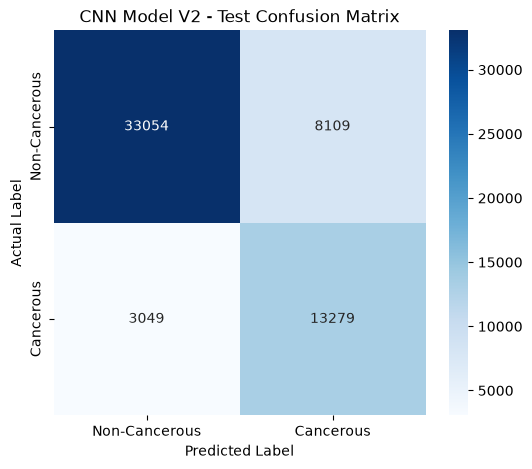

In [49]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions on untouched test dataset
y_test_prob = cnn_model_v2.predict(test_dataset).flatten()

y_test_pred = (y_test_prob >= 0.5).astype(int)

# Calculate metrics
print("TEST ACCURACY:", accuracy_score(y_test, y_test_pred))
print("\nROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Non-Cancerous', 'Cancerous']
))

# Confusion Matrix
cm_test = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Cancerous', 'Cancerous'],
    yticklabels=['Non-Cancerous', 'Cancerous']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('CNN Model V2 - Test Confusion Matrix')
plt.show()

# ROC Curve and AUC

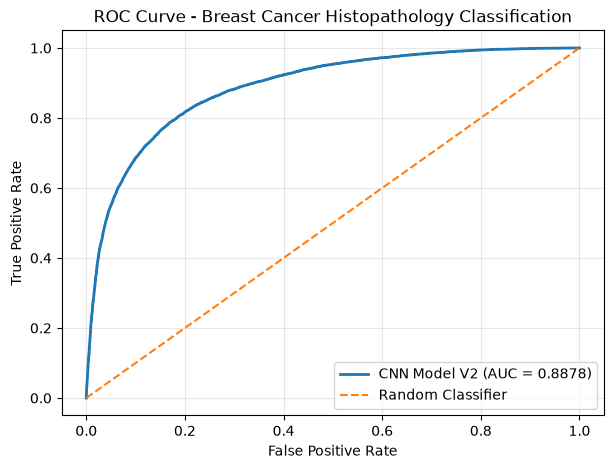

ROC-AUC Score: 0.8878


In [50]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)

roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f'CNN Model V2 (AUC = {roc_auc:.4f})',
    linewidth=2
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Breast Cancer Histopathology Classification')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

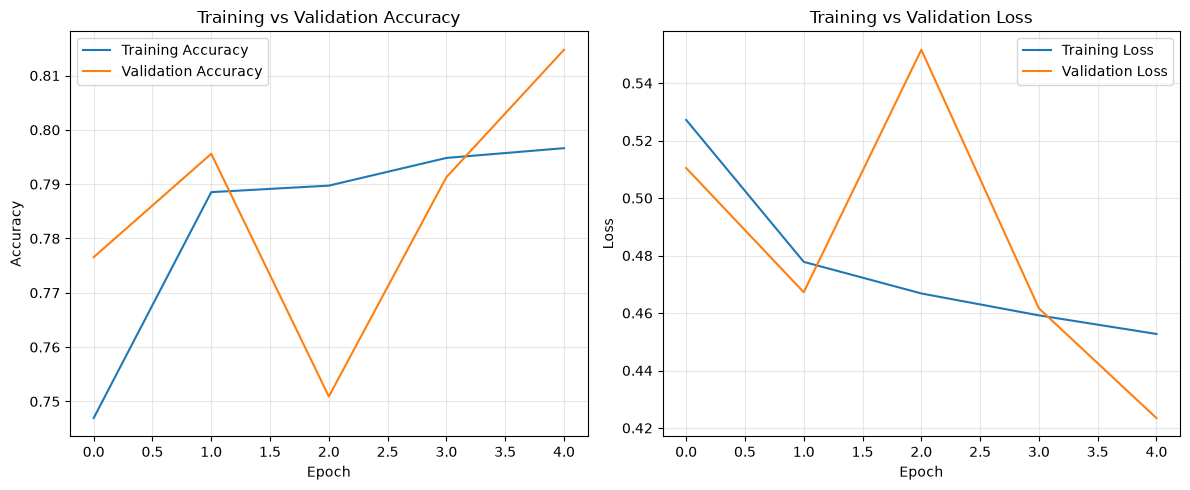

In [51]:
import matplotlib.pyplot as plt

# Training and Validation Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_v2.history['accuracy'], label='Training Accuracy')
plt.plot(history_v2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

# Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history_v2.history['loss'], label='Training Loss')
plt.plot(history_v2.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
# Save trained CNN model
model_path = "breast_cancer_cnn_v2.keras"

cnn_model_v2.save(model_path)

print("Model saved successfully!")
print("File:", model_path)

Model saved successfully!
File: breast_cancer_cnn_v2.keras


In [53]:
import os

if os.path.exists(model_path):
    print("Model file exists!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

Model file exists!
File size: 4.12 MB


In [54]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load saved CNN model
loaded_model = tf.keras.models.load_model(
    "breast_cancer_cnn_v2.keras"
)

print("CNN Model loaded successfully!")

CNN Model loaded successfully!


# Test One Single Image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


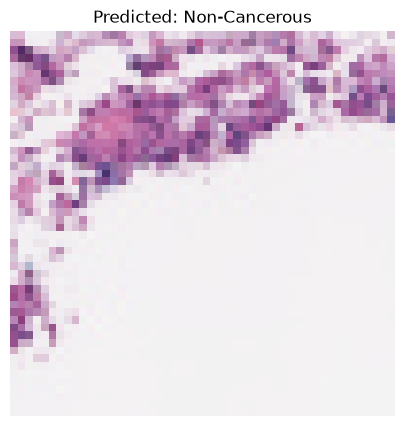

Predicted Class: Non-Cancerous
Cancerous Probability: 33.38 %
Actual Class: Non-Cancerous


In [55]:
# Select one test image
image_path = X_test[0]

# Load and preprocess image
img = Image.open(image_path).convert("RGB")
img = img.resize((50, 50))

img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = loaded_model.predict(img_array)[0][0]

predicted_class = 1 if prediction >= 0.5 else 0

class_names = {
    0: "Non-Cancerous",
    1: "Cancerous"
}

# Display image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis("off")
plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Cancerous Probability:", round(float(prediction) * 100, 2), "%")
print("Actual Class:", class_names[int(y_test[0])])

In [56]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Test Accuracy",
        "Test Loss"
    ],
    "CNN Model V1": [
        0.2754,  # Previous validation accuracy
        None,    # V1 test accuracy not recorded
        None     # V1 test loss not recorded
    ],
    "CNN Model V2": [
        0.8148,
        0.8059,
        0.4271
    ]
})

print(comparison.to_string(index=False))

             Metric  CNN Model V1  CNN Model V2
Validation Accuracy        0.2754        0.8148
      Test Accuracy           NaN        0.8059
          Test Loss           NaN        0.4271


In [57]:
import pandas as pd
import numpy as np

dataset_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Non-Cancerous (Class 0)": [
        np.sum(y_train_balanced == 0),
        np.sum(y_val == 0),
        np.sum(y_test == 0)
    ],
    "Cancerous (Class 1)": [
        np.sum(y_train_balanced == 1),
        np.sum(y_val == 1),
        np.sum(y_test == 1)
    ]
})

dataset_summary["Total Images"] = (
    dataset_summary["Non-Cancerous (Class 0)"] +
    dataset_summary["Cancerous (Class 1)"]
)

print(dataset_summary.to_string(index=False))

   Dataset  Non-Cancerous (Class 0)  Cancerous (Class 1)  Total Images
  Training                    15000                15000         30000
Validation                    27911                10573         38484
   Testing                    41163                16328         57491


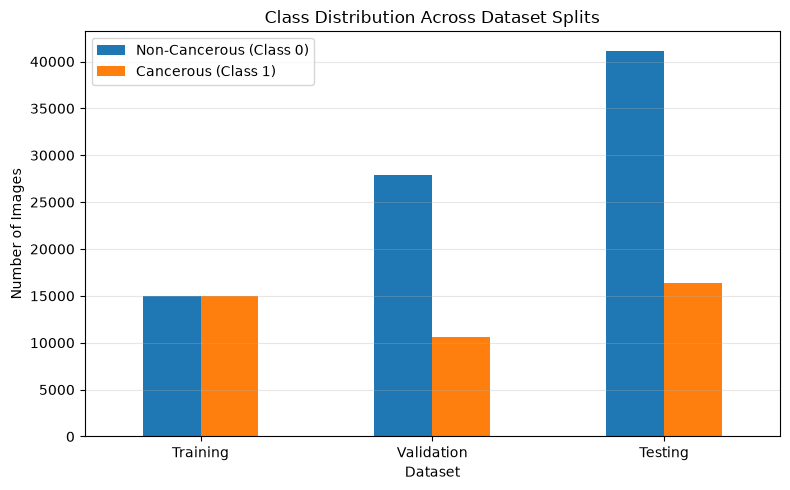

In [58]:
import matplotlib.pyplot as plt

dataset_summary.set_index("Dataset")[
    ["Non-Cancerous (Class 0)", "Cancerous (Class 1)"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display CNN architecture

In [59]:
cnn_model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,066,949 (4.07 MB)

 Trainable params: 355,649 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 711,300 (2.71 MB)

In [60]:
from tensorflow.keras.utils import plot_model

plot_model(
    cnn_model_v2,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=150
)

print("CNN Architecture diagram generated successfully!")

You must install pydot (`pip install pydot`) for `plot_model` to work.
CNN Architecture diagram generated successfully!


In [61]:
%pip install pydot graphviz

Defaulting to user installation because normal site-packages is not writeable
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)

   -------------------- ------------------- 1/2 [graphviz]
   -------------------- ------------------- 1/2 [graphviz]
   -------------------- ------------------- 1/2 [graphviz]
   -------------------- ------------------- 1/2 [graphviz]
   ---------------------------------------- 2/2 [graphviz]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
from tensorflow.keras.utils import plot_model

plot_model(
    cnn_model_v2,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=150
)

print("Architecture diagram generated!")

You must install pydot (`pip install pydot`) for `plot_model` to work.
Architecture diagram generated!


In [63]:
%pip install pydot graphviz

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import shutil

print("Graphviz path:", shutil.which("dot"))

Graphviz path: None


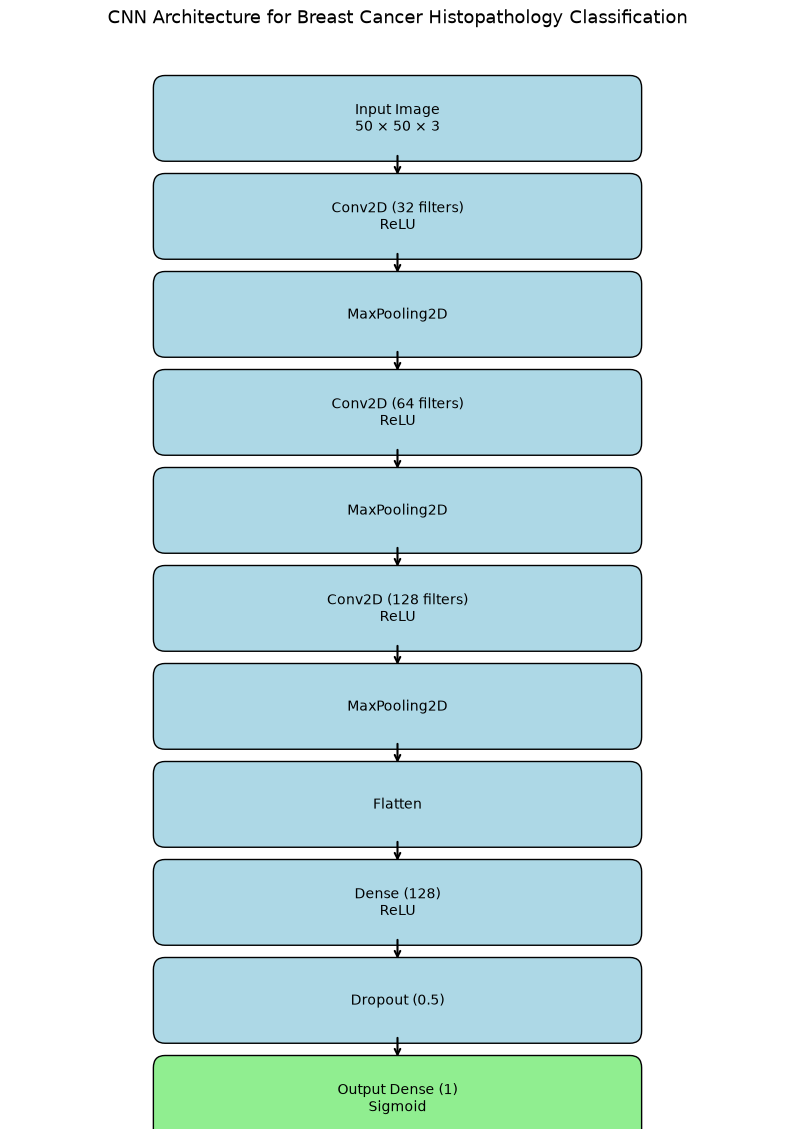

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

layers = [
    "Input Image\n50 × 50 × 3",
    "Conv2D (32 filters)\nReLU",
    "MaxPooling2D",
    "Conv2D (64 filters)\nReLU",
    "MaxPooling2D",
    "Conv2D (128 filters)\nReLU",
    "MaxPooling2D",
    "Flatten",
    "Dense (128)\nReLU",
    "Dropout (0.5)",
    "Output Dense (1)\nSigmoid"
]

fig, ax = plt.subplots(figsize=(10, 14))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(layers) * 1.2)
ax.axis("off")

for i, layer in enumerate(layers):
    y = len(layers) * 1.2 - (i + 1) * 1.2

    box = FancyBboxPatch(
        (2, y), 6, 0.75,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue" if i < 10 else "lightgreen"
    )

    ax.add_patch(box)
    ax.text(5, y + 0.37, layer,
            ha="center", va="center", fontsize=10)

    if i < len(layers) - 1:
        ax.annotate(
            "", xy=(5, y - 0.35),
            xytext=(5, y - 0.05),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title("CNN Architecture for Breast Cancer Histopathology Classification",
          fontsize=13, pad=20)

plt.savefig("CNN_Architecture.png", dpi=300, bbox_inches="tight")
plt.show()

In [3]:
hyperparameters = {
    "Parameter": [
        "Input Image Size",
        "Image Channels",
        "CNN Convolution Layers",
        "Filters",
        "Activation Function",
        "Pooling",
        "Dense Layer",
        "Dropout",
        "Output Activation",
        "Optimizer",
        "Learning Rate",
        "Loss Function",
        "Batch Size",
        "Epochs"
    ],
    "Configuration": [
        "50 × 50",
        "3 (RGB)",
        "3",
        "32, 64, 128",
        "ReLU",
        "MaxPooling (2 × 2)",
        "128 neurons",
        "0.5",
        "Sigmoid",
        "Adam",
        "0.0001",
        "Binary Crossentropy",
        "64",
        "5"
    ]
}

hyperparameter_df = pd.DataFrame(hyperparameters)

display(hyperparameter_df)

NameError: name 'pd' is not defined

In [4]:
import pandas as pd

In [5]:
hyperparameter_df = pd.DataFrame(hyperparameters)

display(hyperparameter_df)

,Parameter,Configuration
0,Input Image Size,50 × 50
1,Image Channels,3 (RGB)
2,CNN Convolution Layers,3
3,Filters,"32, 64, 128"
4,Activation Function,ReLU
5,Pooling,MaxPooling (2 × 2)
6,Dense Layer,128 neurons
7,Dropout,0.5
8,Output Activation,Sigmoid
9,Optimizer,Adam


# Calculate model parameters

In [6]:
# CNN Model Complexity Analysis

total_params = cnn_model_v2.count_params()

trainable_params = sum(
    np.prod(v.shape) for v in cnn_model_v2.trainable_weights
)

non_trainable_params = sum(
    np.prod(v.shape) for v in cnn_model_v2.non_trainable_weights
)

print("CNN MODEL COMPLEXITY")
print("-----------------------------")
print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)

print("\nDetailed Model Architecture:")
cnn_model_v2.summary()

NameError: name 'cnn_model_v2' is not defined

In [7]:
import tensorflow as tf
import numpy as np

cnn_model_v2 = tf.keras.models.load_model(
    "breast_cancer_cnn_v2.keras"
)

print("CNN Model V2 loaded successfully!")

CNN Model V2 loaded successfully!


In [8]:
total_params = cnn_model_v2.count_params()

trainable_params = sum(
    np.prod(v.shape) for v in cnn_model_v2.trainable_weights
)

non_trainable_params = sum(
    np.prod(v.shape) for v in cnn_model_v2.non_trainable_weights
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)

cnn_model_v2.summary()

Total Parameters: 355649
Trainable Parameters: 355649
Non-Trainable Parameters: 0


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,066,949 (4.07 MB)

 Trainable params: 355,649 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 711,300 (2.71 MB)

# Conclusion

## Conclusion

This study presents a Convolutional Neural Network (CNN)-based approach for the classification of breast cancer histopathology images into non-cancerous and cancerous categories. The proposed framework was developed using the Breast Histopathology Images dataset, with image preprocessing, patient-wise data partitioning, and balanced training samples to establish a reliable experimental workflow.

The developed CNN architecture incorporates multiple convolutional and max-pooling layers to extract relevant spatial features from histopathological image patches. The model achieved a validation accuracy of 81.48% and a test accuracy of 80.59%, with a test loss of 0.4271. The validation classification results demonstrated an F1-score of 0.87 for the non-cancerous class and 0.69 for the cancerous class. These findings indicate that the proposed model can learn discriminative features from histopathological images, although its performance varies between the two classes.

Despite these promising results, further improvements are required, particularly in the identification of cancerous image patches. Future work will focus on data augmentation, hyperparameter optimization, transfer learning, and the evaluation of advanced deep learning architectures to improve classification performance and generalization.

Overall this work establishes an experimental foundation for automated breast cancer histopathology image classification using deep learning. The proposed system is intended for research purposes and requires further independent validation before any potential clinical application.